In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/student_cleaned.csv")

In [ ]:
df.head()

,Student_ID,Name,Gender,Age,Department,Semester,CGPA,Attendance,Placement_Status,City,Hostel,Family_Income,Backlogs,Study_Hours,Internship
0,1001,Simran Sharma,Female,19.0,ECE,3,8.67,94.0,Placed,Ludhiana,No,266653,0,1.7,Yes
1,1002,Muskan Arora,Male,22.0,ECE,7,6.45,97.0,Not Placed,Jalandhar,Yes,534829,3,3.4,Yes
2,1003,Rohit Patel,Male,18.0,ME,2,7.04,82.0,Not Placed,Jalandhar,Yes,1163483,4,1.9,No
3,1004,Rahul Joshi,Female,24.0,EEE,6,7.98,64.0,Not Placed,Delhi,Yes,806890,0,7.0,Yes
4,1005,Riya Gupta,Female,23.0,IT,3,7.09,73.0,Not Placed,Jalandhar,Yes,1477440,1,4.7,Yes


Pattern Detection is the process of discovering meaningful and recurring relationships or trends in data. For example, you may find that students with higher attendance and more study hours generally have higher CGPAs, or that placement rates differ by department. Such patterns can be identified using correlation matrices, group-by analysis, scatter plots, and clustering.

Group comparisons: Compare average CGPA by department or semester. A department with consistently higher CGPA reveals a pattern.

In [ ]:
avg_cgpa = df.groupby("Department")["CGPA"].mean()
print(avg_cgpa)

Department
CE     7.658734
CSE    7.717106
ECE    7.714908
EEE    7.599123
IT     7.693546
ME     7.792504
Name: CGPA, dtype: float64


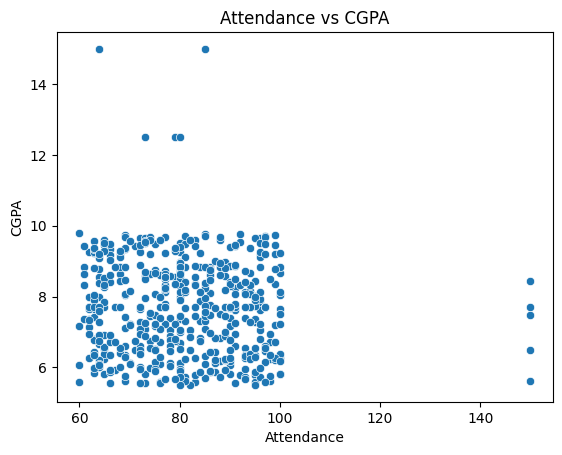

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x="Attendance", y="CGPA")
plt.title("Attendance vs CGPA")
plt.show()

Z-score method for anomalies: Compute the standardized score of CGPA or attendance. Observations with ∣z∣>3 are potential anomalies.

A z-score, also called a standard score, indicates the position of a raw score relative to the mean of a dataset, expressed in terms of standard deviations. A z-score of 0 means the value is exactly at the mean, a positive z-score indicates the value is above the mean, and a negative z-score indicates it is below the mean. Z-scores allow comparison across different datasets or scales by standardizing values on a common scale, making raw numbers easier to interpret and compare.

In [ ]:
from scipy.stats import zscore

df["CGPA_z"] = zscore(df["CGPA"])
anomalies = df[df["CGPA_z"].abs() > 3]
print(anomalies[["Student_ID", "CGPA", "CGPA_z"]])

     Student_ID  CGPA    CGPA_z
16         1017  15.0  5.301678
55         1056  12.5  3.488188
262        1263  12.5  3.488188
337        1338  15.0  5.301678
406        1407  12.5  3.488188


Detecting a Pattern with a Pivot Table

Pivot Tables allow you to summarize and analyze large datasets efficiently, making it easier to detect patterns, trends, and anomalies.

Find the average placement rate by department and semester.

This reveals patterns such as departments or semesters with consistently higher placement rates.

In [ ]:
placement_pattern = pd.pivot_table(
    df,
    values="Placement_Status",
    index="Department",
    columns="Semester",
    aggfunc=lambda x: (x == "Placed").mean() * 100
)
print(placement_pattern)

Semester            1          2          3          4          5          6  \
Department                                                                     
CE          30.769231  11.111111  33.333333  50.000000  22.222222  28.571429   
CSE         33.333333  11.111111  43.750000  41.666667  61.538462  18.181818   
ECE         60.000000  54.545455  44.444444  20.000000   0.000000  33.333333   
EEE         12.500000  33.333333  53.846154  28.571429  20.000000  42.857143   
IT          20.000000  44.444444  50.000000  21.428571  44.444444  50.000000   
ME           9.090909  40.000000   0.000000  36.363636  40.000000  53.333333   

Semester            7          8  
Department                        
CE           0.000000  26.666667  
CSE         33.333333  50.000000  
ECE         30.000000  33.333333  
EEE          0.000000  35.714286  
IT          16.666667  20.000000  
ME          36.363636  71.428571  


Finding Patterns with Clustering: Students in the same cluster exhibit similar academic behavior.

Clustering is an unsupervised machine learning technique used to group similar data points together without using labelled data. It helps discover hidden patterns or natural groupings in datasets by placing similar data points into the same cluster.

In [ ]:
from sklearn.cluster import KMeans

X = df[["CGPA", "Attendance"]]
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(X)

print(df[["CGPA", "Attendance", "Cluster"]].head())

   CGPA  Attendance  Cluster
0  8.67        94.0        0
1  6.45        97.0        0
2  7.04        82.0        0
3  7.98        64.0        1
4  7.09        73.0        1


Anomaly Identification (or outlier detection) involves finding observations that differ markedly from the rest of the data. In the student dataset, a CGPA of 12 or an attendance of 150% would clearly be anomalies. Even realistic but unusual cases, such as a student with very high study hours but extremely low CGPA, may warrant further investigation.

In [ ]:
Q1 = df["CGPA"].quantile(0.25)
Q3 = df["CGPA"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["CGPA"] < lower) | (df["CGPA"] > upper)]
print(outliers)

     Student_ID          Name Gender   Age Department  Semester  CGPA  \
16         1017  Deepak Mehta   Male  21.0        ECE         5  15.0   
55         1056   Komal Arora   Male  22.0        EEE         2  12.5   
262        1263   Harsh Singh   Male  22.0        CSE         4  12.5   
337        1338  Muskan Joshi   Male  23.0         IT         4  15.0   
406        1407  Simran Arora   Male  21.0        EEE         5  12.5   

     Attendance Placement_Status       City Hostel  Family_Income  Backlogs  \
16         64.0       Not Placed       Pune    Yes         306091         4   
55         73.0       Not Placed   Amritsar     No         370262         1   
262        79.0       Not Placed  Jalandhar     No         989526         2   
337        85.0       Not Placed     Mumbai    Yes        1362978         1   
406        80.0       Not Placed  Jalandhar     No         472028         4   

     Study_Hours Internship    CGPA_z  Cluster  
16           6.9        Yes  5.301678

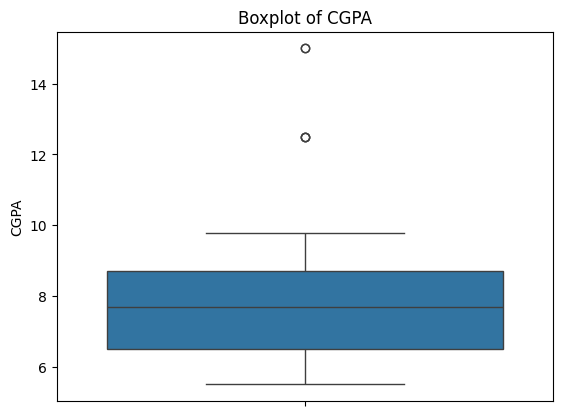

In [ ]:
sns.boxplot(y=df["CGPA"])
plt.title("Boxplot of CGPA")
plt.show()

In [ ]:
# contamination refers to the proportion of outliers or anomilies expected in the dataset. 0.05 means 5% it ranks the top 5% of points with highest anamoly
from sklearn.ensemble import IsolationForest

X = df[["CGPA", "Attendance", "Study_Hours"]]

iso = IsolationForest(contamination=0.05, random_state=42)
df["Anomaly"] = iso.fit_predict(X)

anomalies = df[df["Anomaly"] == -1]
print(anomalies[["Student_ID", "CGPA", "Attendance", "Study_Hours"]])

     Student_ID       CGPA  Attendance  Study_Hours
5          1006   8.440000       150.0          2.9
16         1017  15.000000        64.0          6.9
33         1034   5.610000       150.0          7.2
55         1056  12.500000        73.0          2.7
58         1059   9.550000        92.0          1.3
72         1073   9.380000        94.0          7.9
122        1123   5.820000       100.0          7.7
143        1144   9.250000        63.0          8.0
154        1155   7.694104       150.0          2.5
172        1173   9.560000        63.0          1.5
177        1178   6.670000        64.0          1.1
220        1221   8.820000        61.0          1.4
239        1240   5.740000        98.0          1.0
240        1241   5.590000        97.0          7.7
248        1249   5.520000        80.0          1.2
262        1263  12.500000        79.0          4.2
271        1272   5.580000        60.0          1.9
301        1302   9.790000        60.0          7.3
337        1